<a href="https://colab.research.google.com/github/senisekoni32-a11y/ml_internship_tasks/blob/main/Task_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split as tts

df = pd.read_csv('iris.csv')

X = df.drop('species', axis=1)
y = df['species']

X_train, X_test, y_train, y_test = tts(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print('Train accuracy:', accuracy_score(y_train, tree.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))
print('Depth:', tree.get_depth())

Train accuracy: 1.0
Test accuracy: 0.9333333333333333
Depth: 5


In [6]:
for d in [1, 2, 3, 4, 5]:
    pruned = DecisionTreeClassifier(max_depth=d, random_state=42)
    pruned.fit(X_train, y_train)
    print(d, accuracy_score(y_train, pruned.predict(X_train)), accuracy_score(y_test, pruned.predict(X_test)))

1 0.6666666666666666 0.6666666666666666
2 0.9666666666666667 0.9333333333333333
3 0.9833333333333333 0.9666666666666667
4 0.9916666666666667 0.9333333333333333
5 1.0 0.9333333333333333


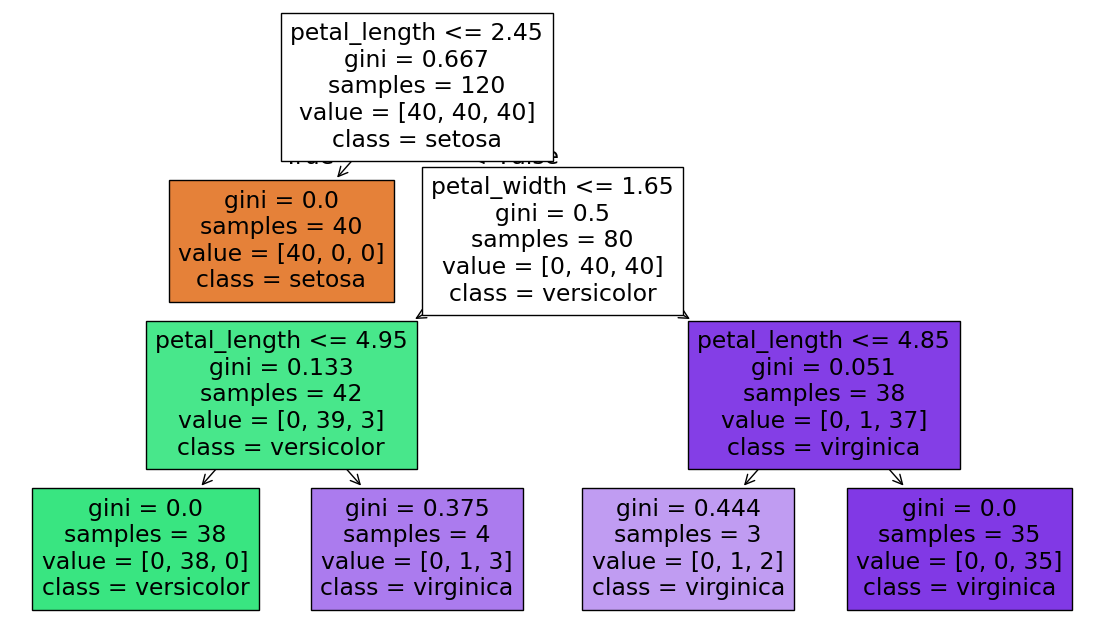

In [7]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

best = DecisionTreeClassifier(max_depth=3, random_state=42)
best.fit(X_train, y_train)

plt.figure(figsize=(14, 8))
plot_tree(best, feature_names=X.columns, class_names=best.classes_, filled=True)
plt.show()